# **Multiclass SVM**

Let's create 4 set of classes of 2D points manually and spread them across the 4 classes to force the data to be split.

In [111]:
import numpy as np
from sklearn import svm
import matplotlib.pyplot as plt
from scipy.stats import mode
from itertools import combinations

X = np.array([[1, 6], [1, 7], [2, 5], [2, 8],
                     [4, 2], [4, 3], [5, 1], [5, 2],
                     [5, 3], [6, 1], [6, 2], [9, 4],
                     [9, 7], [10, 5], [10, 6], [11, 6],
                     [5, 9], [5, 10], [5, 11], [6, 9],
                     [6, 10], [7, 10], [8, 11]])
y = np.array([1, 1, 1, 1,
                     2, 2, 2, 2, 2, 2, 2,
                     3, 3, 3, 3, 3,
                     4, 4, 4, 4, 4, 4, 4])

Transform into 4 binary classes


In [112]:
y_1 = np.where(y == 1, 1, -1)
y_2 = np.where(y == 2, 1, -1)
y_3 = np.where(y == 3, 1, -1)
y_4 = np.where(y == 4, 1, -1)

Plotting the toy example of the 4 classes

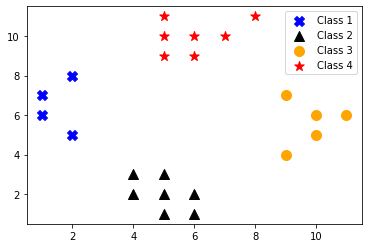

In [113]:
plt.scatter(X[y_1==1, 0], X[y_1==1, 1], s=100, marker='X', c='blue', label ='Class 1')
plt.scatter(X[y_2==1, 0], X[y_2==1, 1], s=100, marker='^', c='black', label ='Class 2')
plt.scatter(X[y_3==1, 0], X[y_3==1, 1], s=100, marker='o', c='orange', label ='Class 3')
plt.scatter(X[y_4==1, 0], X[y_4==1, 1], s=100, marker='*', c='red', label ='Class 4')
plt.legend()
plt.show()

# **One-vs-All Classification (OVA)**

Train one classifier for each using SVM. The decision_function_shape='ovr' flag indicates which method to use




In [114]:
Y = [y_1, y_2, y_3, y_4]

classifiers = []
for y_i in Y:
    clf = svm.SVC(kernel='linear', C=1000, decision_function_shape='ovr')
    clf.fit(X, y_i) # fit the SVM model for each binary classifier
    classifiers.append(clf)

Predict using OVA where the final prediction is the classs of the classifier with the maximum value of the score function




In [115]:
def predict_class(X, classifiers):
    predictions = np.zeros((X.shape[0], len(classifiers)))
    for idx, clf in enumerate(classifiers):
        predictions[:, idx] = clf.decision_function(X) # the score i.e the signed distance to the seperating hyperplane w^T.X + b = 0

    # return the argmax of the score function
    return np.argmax(predictions, axis=1) + 1

Make predictions on two test examples: check the plot and tell me what should the class prediction be?




In [116]:
X_test = np.array([[5,4],[2,4]])
Z_test = predict_class(X_test, classifiers)
print(Z_test) # should print [2 1]

[2 1]


Plot the fitted multiclass SVM model on the trained data

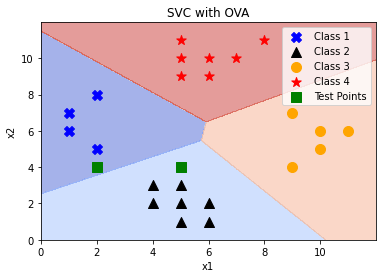

In [117]:
# create a mesh to plot in
h = 0.02  # step size in the mesh
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                    np.arange(y_min, y_max, h))

Z = predict_class(np.c_[xx.ravel(), yy.ravel()], classifiers)

# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.5)

# Plot also the training points
plt.scatter(X[y_1==1, 0], X[Y[0]==1, 1], s=100, marker='X', c='blue', label ='Class 1')
plt.scatter(X[y_2==1, 0], X[Y[1]==1, 1], s=100, marker='^', c='black', label ='Class 2')
plt.scatter(X[y_3==1, 0], X[Y[2]==1, 1], s=100, marker='o', c='orange', label ='Class 3')
plt.scatter(X[y_4==1, 0], X[Y[3]==1, 1], s=100, marker='*', c='red', label ='Class 4')
plt.xlabel('x1')
plt.ylabel('x2')
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.title('SVC with OVA')
plt.legend()

#Plot the test points predictions
plt.scatter(X_test[:, 0], X_test[:, 1], s=100, marker='s', c='green', label ='Test Points')
plt.legend()

plt.show()


We can see that point [5,4] [2,4] indeed were predicted correctly to classes [2, 1]

# **One-vs-One Classification (OVO)**

Creating N(N-1)/2 classifiers to train seperately. I use combinations to create all possible pairs of classes

In [118]:
training_data = []
class_pairs = list(combinations(set(y), 2))
for class_pair in class_pairs: # make sure you assign + labels to one class and - labels to the other one - this is different then OVA
    class_mask = np.where((y == class_pair[0]) | (y == class_pair[1]))
    y_i = np.where(y[class_mask] == class_pair[0], 1, -1)
    training_data.append((X[class_mask], y_i))
  
#print(training_data)

Train N(N-1)/2 classifiers. 'ovo' is the default method used in sklearn

In [119]:
classifiers = []
for data in training_data:
    clf = svm.SVC(kernel='linear', C=1000, decision_function_shape='ovo')
    clf.fit(data[0], data[1]) # fit the SVM model for each binary classifier on the X and y for each pair of classifiers
    classifiers.append(clf)

Predict using OVA where the final prediction is the classs of the classifier with the maximum value of the score function

In [120]:
def predict_class(X, classifiers, class_pairs):
    predictions = np.zeros((X.shape[0], len(classifiers)))
    for idx, clf in enumerate(classifiers):
        class_pair = class_pairs[idx]
        prediction = clf.predict(X)
        predictions[:, idx] = np.where(prediction == 1, class_pair[0], class_pair[1])
    return mode(predictions, axis=1)[0].ravel().astype(int), predictions # use mode to return the frequently repeated number in predictions i.e. the highest voting class

Make predictions on two test examples: check the plot and tell me what should the class prediction be?

In [121]:
X_test = np.array([[5,4],[2,4]])
Z_test, predictions = predict_class(X_test, classifiers, class_pairs)
print('Classification results per point', Z_test) # should print [2 1]
print('Votes for each pair of class', predictions) # shows that the first point got 3 votes for class 2 (highest) and second point got 3 votes for class 1 (highest)

Classification results per point [2 1]
Votes for each pair of class [[2. 1. 1. 2. 2. 3.]
 [1. 1. 1. 2. 2. 4.]]


Plot the fitted multiclass SVM model on the trained data

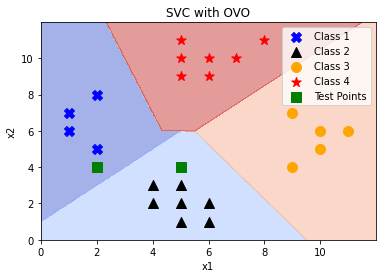

In [122]:
# create a mesh to plot in
h = 0.02  # step size in the mesh
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                    np.arange(y_min, y_max, h))

Z, _ = predict_class(np.c_[xx.ravel(), yy.ravel()], classifiers, class_pairs)

# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, cmap=plt.cm.coolwarm, alpha=0.5)

# Plot also the training points
plt.scatter(X[y_1==1, 0], X[Y[0]==1, 1], s=100, marker='X', c='blue', label ='Class 1')
plt.scatter(X[y_2==1, 0], X[Y[1]==1, 1], s=100, marker='^', c='black', label ='Class 2')
plt.scatter(X[y_3==1, 0], X[Y[2]==1, 1], s=100, marker='o', c='orange', label ='Class 3')
plt.scatter(X[y_4==1, 0], X[Y[3]==1, 1], s=100, marker='*', c='red', label ='Class 4')
plt.xlabel('x1')
plt.ylabel('x2')
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.title('SVC with OVO')
plt.legend()

#Plot the test points predictions
plt.scatter(X_test[:, 0], X_test[:, 1], s=100, marker='s', c='green', label ='Test Points')
plt.legend()

plt.show()
